# ToysAD-8K Cross-View Identity Freeze

**Notebook file:** `08f-toysad8k-cross-view-identity-freeze.ipynb`

This notebook tests whether the same automatically detected object can be linked across two to five uploaded views. It consumes the locked LocateAnything, SAM 2.1, DINOv2-small, and P1 outputs from Notebook 08E. It compares DINO global-embedding matching with one bounded normalized-geometry variant and freezes the simplest method justified by development evidence.

The final figures show the actual automatic odd-one-out result, its object masks, and the supporting P1 heatmaps. Human correction remains an optional review feature after the automatic result. It is not part of the main model path.

## Saved-output evidence copy

This notebook records the completed run for repository review. Its code and markdown match the clean runnable notebook. Private scene visuals and identifier-bearing output were removed. Safe aggregate tables and charts were retained.

Run stage: `08F Kaggle Version 1`  
Clean notebook SHA-256: `fb2f9b3d69874d7ad252ee2f338f19c94499ed162c9445bf25c84a18452e1f8f`  
Downloaded saved-output SHA-256: `7a489422c88a3c8f22e4b6921cfced1ecabd205051e747980e7f49abd2dfdef8`


## Evaluation boundary

The stage follows a strict order:

1. Verify every Notebook 08E prediction, embedding, index, and lock hash.
2. Produce embedding-only and normalized-geometry identity predictions.
3. Test two, three, and five arbitrary views, reversed input order, one missing view, and duplicate-view rejection.
4. Lock all identity predictions and their configuration hashes.
5. Only then open evaluator correspondence and base-asset cluster fields.
6. Report coverage, unmatched rate, ambiguity rate, switch rate, pairwise identity accuracy, and cycle consistency with base-asset-clustered intervals.
7. Freeze one method and a versioned web-application output contract.

The method resource also binds the exact Notebook 08E base-model identity. A later stage cannot silently change the LocateAnything prompt or cleanup, SAM 2.1 configuration, DINOv2-small configuration, preprocessing, or output schema while claiming to use this freeze.

ToysAD camera metadata is allowed only as an evaluator diagnostic. It cannot enter either candidate method or the selected web method. No arbitrary universal accuracy threshold is used. The normalized-geometry candidate is selected only when paired clustered evidence shows a favorable change, no adverse change, and all structural stability checks pass.

In [1]:
from __future__ import annotations

import json
import os
from pathlib import Path
import subprocess
import sys

import pandas as pd
from IPython.display import Image as NotebookImage, display

sys.dont_write_bytecode = True

NOTEBOOK_NAME = "08f-toysad8k-cross-view-identity-freeze.ipynb"
EXECUTION_ENVIRONMENT = "kaggle" if Path("/kaggle/input").is_dir() else "workspace"
OUTPUT_ROOT = Path(os.getenv(
    "VPI_08F_OUTPUT_ROOT",
    "/kaggle/working/toysad8k_cross_view_identity_freeze"
    if EXECUTION_ENVIRONMENT == "kaggle"
    else ".local/runs/toysad8k-cross-view-identity-freeze",
)).expanduser().resolve()

In [2]:
def mounted_roots() -> list[Path]:
    """Return dataset and notebook mounts without their container directories."""
    root = Path("/kaggle/input")
    if not root.is_dir():
        return []
    candidates = [path for path in root.iterdir()
                  if path.is_dir() and path.name not in {"datasets", "notebooks", "models"}]
    for pattern in ("datasets/*/*", "notebooks/*/*", "models/*/*/*/*"):
        for path in root.glob(pattern):
            if not path.is_dir():
                continue
            versions = path / "versions"
            if versions.is_dir():
                candidates.extend(child for child in versions.iterdir() if child.is_dir())
            else:
                candidates.append(path)
    return sorted({path.resolve() for path in candidates}, key=lambda path: path.as_posix())


def configured_paths(variable: str) -> list[Path]:
    value = os.getenv(variable, "").strip()
    if not value:
        return []
    return [Path(item).expanduser() for item in value.split(os.pathsep) if item]


def find_code_root() -> Path:
    candidates = configured_paths("VPI_CODE_ROOT")
    candidates.extend((Path.cwd(), *Path.cwd().parents, *mounted_roots()))
    for candidate in candidates:
        if (candidate / "scripts/run_cross_view_identity_freeze.py").is_file():
            return candidate.resolve()
        if (candidate / "code" / "scripts/run_cross_view_identity_freeze.py").is_file():
            return (candidate / "code").resolve()
    raise FileNotFoundError("The Visual Peer Inspector code snapshot was not found")


def find_prediction_roots() -> list[Path]:
    configured = configured_paths("VPI_08E_PREDICTION_ROOTS")
    if configured:
        roots = [path.resolve() for path in configured]
    else:
        roots = []
        patterns = (
            "prediction_manifest.jsonl",
            "*/model-safe/prediction_manifest.jsonl",
            "*/*/model-safe/prediction_manifest.jsonl",
            "*/*/*/model-safe/prediction_manifest.jsonl",
        )
        for mounted in mounted_roots():
            for pattern in patterns:
                roots.extend(path.parent.resolve() for path in mounted.glob(pattern))
    unique = sorted(set(roots), key=lambda path: path.as_posix())
    if not unique:
        raise FileNotFoundError("No Notebook 08E model-safe prediction root was found")
    return unique


def find_marker(name: str, variable: str) -> Path:
    configured = configured_paths(variable)
    candidates = configured + mounted_roots()
    matches = []
    for candidate in candidates:
        direct = candidate / name
        if direct.is_file():
            matches.append(direct.resolve())
        for pattern in (f"*/{name}", f"*/*/{name}", f"*/*/*/{name}"):
            matches.extend(path.resolve() for path in candidate.glob(pattern) if path.is_file())
    unique = sorted(set(matches), key=lambda path: path.as_posix())
    if len(unique) != 1:
        raise FileNotFoundError(
            f"Expected one {name}; found {len(unique)}. Set {variable} explicitly."
        )
    return unique[0]


def find_media_roots() -> list[Path]:
    configured = configured_paths("VPI_MEDIA_ROOTS")
    if configured:
        return sorted({path.resolve() for path in configured})
    roots = []
    for mounted in mounted_roots():
        if (mounted / "media").is_dir():
            roots.append(mounted.resolve())
        for child in mounted.glob("*/model-input"):
            if (child / "media").is_dir():
                roots.append(child.resolve())
    unique = sorted(set(roots), key=lambda path: path.as_posix())
    if not unique:
        raise FileNotFoundError("No released RGB media roots were found")
    return unique


def code_environment() -> dict[str, str]:
    environment = os.environ.copy()
    source_root = str(CODE_ROOT / "src")
    previous = environment.get("PYTHONPATH")
    environment["PYTHONPATH"] = source_root if not previous else source_root + os.pathsep + previous
    return environment


def read_secret(name: str) -> str | None:
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    except Exception:
        return os.getenv(name)

## Locate and verify the locked inputs

In [3]:
CODE_ROOT = find_code_root()
sys.path.insert(0, str(CODE_ROOT / "src"))
from visual_peer_inspector.notebook_provenance import verify_notebook_code_snapshot

CODE_PROVENANCE = verify_notebook_code_snapshot(
    CODE_ROOT,
    "notebooks/development-freeze/08f-toysad8k-cross-view-identity-freeze.ipynb",
)
PREDICTION_ROOTS = find_prediction_roots()
EVALUATOR_PATH = find_marker(
    "evaluator_correspondence.jsonl",
    "VPI_EVALUATOR_CORRESPONDENCE",
)
MEDIA_ROOTS = find_media_roots()

from visual_peer_inspector.workflows.cross_view_identity_freeze import load_08e_predictions

verified = load_08e_predictions(PREDICTION_ROOTS)
display({
    "environment": EXECUTION_ENVIRONMENT,
    "input cohorts": list(verified.cohort_ids),
    "scene count": len(verified.views_by_scene),
    "embedding dimension": verified.embedding_dimension,
    "verified Notebook 08E locks": len(verified.input_lock_sha256s),
})

{'environment': 'kaggle',
 'input cohorts': ['toysad8k-development-confirm-300-v1',
  'toysad8k-development-remainder-600-v1',
  'toysad8k-development-screen-100-v1'],
 'scene count': 1000,
 'embedding dimension': 384,
 'verified Notebook 08E locks': 3}

## Run the prediction-first identity freeze

In [4]:
# ClearML runs only after the complete workflow has written its local evidence.
# A separate child process bounds tracking so a network delay cannot hold the stage.
environment = code_environment()
clearml_access = read_secret("CLEARML_API_ACCESS_KEY")
clearml_secret = read_secret("CLEARML_API_SECRET_KEY")
clearml_mode = "online" if clearml_access and clearml_secret else "disabled"
if clearml_mode == "online":
    try:
        subprocess.run(
            [
                sys.executable, "-m", "pip", "install", "-q", "-r",
                str(CODE_ROOT / "requirements/confirmation-tracking-lock.txt"),
            ],
            check=True,
            timeout=180,
            env=environment,
        )
    except Exception as error:
        clearml_mode = "disabled"
        print(f"ClearML dependency setup was unavailable: {type(error).__name__}")
if clearml_mode == "online":
    environment.update({
        "CLEARML_API_ACCESS_KEY": clearml_access,
        "CLEARML_API_SECRET_KEY": clearml_secret,
        "CLEARML_API_HOST": "https://api.clear.ml",
        "CLEARML_WEB_HOST": "https://app.clear.ml",
        "CLEARML_FILES_HOST": "https://files.clear.ml",
    })

command = [
    sys.executable,
    str(CODE_ROOT / "scripts/run_cross_view_identity_freeze.py"),
]
for path in PREDICTION_ROOTS:
    command.extend(("--prediction-root", str(path)))
for path in MEDIA_ROOTS:
    command.extend(("--media-root", str(path)))
command.extend((
    "--evaluator-correspondence", str(EVALUATOR_PATH),
    "--output-root", str(OUTPUT_ROOT),
    "--clearml-mode", clearml_mode,
    "--clearml-wall-time-seconds", "180",
))
subprocess.run(command, check=True, env=environment)

SAFE_ROOT = OUTPUT_ROOT / "safe"
run_record = json.loads((SAFE_ROOT / "run_record.json").read_text(encoding="utf-8"))
display({
    "status": run_record["status"],
    "scenes": run_record["scene_count"],
    "identity predictions": run_record["prediction_count"],
    "resumed predictions": run_record["resumed_from_verified_receipts"],
    "chosen method": run_record["chosen_variant"],
    "odd-one-out panels": run_record["qualitative_panel_count"],
})

{"event": "identity_inputs_verified", "scene_count": 1000}
{"event": "identity_predictions_checkpointed", "completed_scenes": 25, "total_scenes": 1000, "processed_cases": 200, "resumed_cases": 0, "failed_cases": 0}
{"event": "identity_predictions_checkpointed", "completed_scenes": 50, "total_scenes": 1000, "processed_cases": 400, "resumed_cases": 0, "failed_cases": 0}
{"event": "identity_predictions_checkpointed", "completed_scenes": 75, "total_scenes": 1000, "processed_cases": 600, "resumed_cases": 0, "failed_cases": 0}
{"event": "identity_predictions_checkpointed", "completed_scenes": 100, "total_scenes": 1000, "processed_cases": 800, "resumed_cases": 0, "failed_cases": 0}
{"event": "identity_predictions_checkpointed", "completed_scenes": 125, "total_scenes": 1000, "processed_cases": 1000, "resumed_cases": 0, "failed_cases": 0}
{"event": "identity_predictions_checkpointed", "completed_scenes": 150, "total_scenes": 1000, "processed_cases": 1200, "resumed_cases": 0, "failed_cases": 0}


{'status': 'complete',
 'scenes': 1000,
 'identity predictions': 6000,
 'resumed predictions': 0,
 'chosen method': 'embedding_only',
 'odd-one-out panels': 15}

## Structural checks and stability

In [5]:
gates = pd.read_csv(SAFE_ROOT / "acceptance_gates.csv")
stability = pd.read_csv(SAFE_ROOT / "stability_summary.csv")
display(gates)
display(stability)

if not bool(gates["passed"].all()):
    failed = gates.loc[~gates["passed"].astype(bool), "gate"].tolist()
    raise RuntimeError(f"Notebook 08F acceptance gates did not pass: {failed}")

,gate,passed
0,08e_prediction_locks_verified,True
1,identity_predictions_locked_before_evaluator,True
2,two_three_five_view_cases_complete,True
3,input_order_invariance,True
4,duplicate_view_rejection,True
5,missing_view_execution,True
6,no_model_or_render_failures,True
7,method_and_application_contract_frozen,True
8,versioned_application_results_written,True
9,deployment_valid_odd_one_out_evidence,True


,variant,scene_count,order_invariance_rate,duplicate_rejection_rate,missing_view_completion_rate,mean_retained_link_stability
0,embedding_only,1000,1.0,1.0,1.0,1.0
1,normalized_geometry,1000,1.0,1.0,1.0,1.0


## Identity metrics and clustered uncertainty

In [6]:
summary = pd.read_csv(SAFE_ROOT / "method_summary.csv")
intervals = pd.read_csv(SAFE_ROOT / "clustered_intervals.csv")
paired = pd.read_csv(SAFE_ROOT / "paired_method_intervals.csv")

display(summary)
display(intervals)
display(paired)

# Two-view cycle consistency is not defined because a cycle needs three views.
# It remains explicit as not applicable rather than being reported as a perfect score.

,variant,view_count,metric,mean,scene_count,eligible_scene_count,status
0,embedding_only,2,observation_coverage,0.816230,1000,1000,reported
1,embedding_only,2,unmatched_rate,0.183862,1000,1000,reported
2,embedding_only,2,ambiguity_rate,0.505665,1000,1000,reported
3,embedding_only,2,pairwise_identity_accuracy,0.364413,1000,932,reported
4,embedding_only,2,switch_rate,0.635587,1000,932,reported
5,embedding_only,2,cycle_consistency_rate,NaN,1000,0,not_applicable
6,embedding_only,3,observation_coverage,0.887921,1000,1000,reported
7,embedding_only,3,unmatched_rate,0.118873,1000,1000,reported
8,embedding_only,3,ambiguity_rate,0.745223,1000,1000,reported
9,embedding_only,3,pairwise_identity_accuracy,0.336025,1000,974,reported


,variant,view_count,metric,mean,ci_lower,ci_upper,scene_count,cluster_count,repetitions,seed,status
0,embedding_only,2,observation_coverage,0.816230,0.795587,0.836054,1000,273,10000,32240,reported
1,embedding_only,2,unmatched_rate,0.183862,0.165657,0.202630,1000,273,10000,32241,reported
2,embedding_only,2,ambiguity_rate,0.505665,0.485917,0.525808,1000,273,10000,32242,reported
3,embedding_only,2,pairwise_identity_accuracy,0.364413,0.340241,0.389800,932,269,10000,32243,reported
4,embedding_only,2,switch_rate,0.635587,0.610657,0.660300,932,269,10000,32244,reported
5,embedding_only,2,cycle_consistency_rate,NaN,NaN,NaN,0,0,0,32040,not_applicable
6,embedding_only,3,observation_coverage,0.887921,0.872888,0.901659,1000,273,10000,32340,reported
7,embedding_only,3,unmatched_rate,0.118873,0.107050,0.131314,1000,273,10000,32341,reported
8,embedding_only,3,ambiguity_rate,0.745223,0.727415,0.762983,1000,273,10000,32342,reported
9,embedding_only,3,pairwise_identity_accuracy,0.336025,0.321061,0.350875,974,271,10000,32343,reported


,view_count,metric,mean_difference_geometry_minus_embedding,ci_lower,ci_upper,paired_scene_count,cluster_count,repetitions,seed,status
0,2,observation_coverage,-0.018681,-0.023511,-0.013989,1000,273,10000,32240,reported
1,2,unmatched_rate,0.018590,0.014077,0.023323,1000,273,10000,32241,reported
2,2,ambiguity_rate,-0.043041,-0.051607,-0.034289,1000,273,10000,32242,reported
3,2,pairwise_identity_accuracy,-0.000844,-0.010291,0.008379,928,269,10000,32243,reported
4,2,switch_rate,0.000844,-0.008564,0.010148,928,269,10000,32244,reported
5,2,cycle_consistency_rate,NaN,NaN,NaN,0,0,0,32040,not_applicable
6,3,observation_coverage,-0.014895,-0.018073,-0.011748,1000,273,10000,32340,reported
7,3,unmatched_rate,0.015503,0.012428,0.018655,1000,273,10000,32341,reported
8,3,ambiguity_rate,-0.030727,-0.037911,-0.023687,1000,273,10000,32342,reported
9,3,pairwise_identity_accuracy,-0.001196,-0.009171,0.006705,974,271,10000,32343,reported


## Frozen identity method and web output contract

In [7]:
method_freeze = json.loads((SAFE_ROOT / "method_freeze.json").read_text(encoding="utf-8"))
application_contract = json.loads(
    (SAFE_ROOT / "application_output_contract.json").read_text(encoding="utf-8")
)
display(method_freeze)
display(application_contract)

application_examples = [
    json.loads(line)
    for line in (OUTPUT_ROOT / "downstream" / "application_predictions.jsonl").read_text(encoding="utf-8").splitlines()
    if line
]
display({
    "versioned application results": len(application_examples),
    "supported view counts observed": sorted({row["view_count"] for row in application_examples}),
    "example result hash": application_examples[0]["result_sha256"],
})

{'absolute_performance_threshold_used': False,
 'camera_metadata_used_by_chosen_method': False,
 'chosen_configuration': {'ambiguity_margin': 0.05,
  'geometry_weight': 0.0,
  'unmatched_cost': 0.35},
 'chosen_configuration_sha256': '79182083960a9b115780c71f321e58beb282aa2b452d32f470c538da512af07f',
 'chosen_variant': 'embedding_only',
 'decision_rule': 'Use normalized geometry only when the five-view asset-clustered paired interval shows at least one favorable change, shows no adverse change, and all structural stability checks pass. Otherwise retain the simpler embedding-only method.',
 'favorable_metrics': ['ambiguity_rate'],
 'frozen_model_identity_sha256': 'c7c4c8df023c30884baf0fd2693fdbaece5840f1fb5e8d0788bcc82cb53674d7',
 'harmful_metrics': ['observation_coverage', 'unmatched_rate'],
 'human_correction_position': 'optional_review_after_automatic_result',
 'schema_version': 'visual-peer-08f-workflow/v1',
 'status': 'frozen',
 'structural_stability_passed': True}

{'camera_metadata_scope': 'evaluator_diagnostic_only',
 'forbidden_model_inputs': ['source identifiers',
  'evaluator correspondence',
  'labels',
  'roles',
  'categories',
  'file paths',
  'object order',
  'camera metadata'],
 'frozen_model_identity_sha256': 'c7c4c8df023c30884baf0fd2693fdbaece5840f1fb5e8d0788bcc82cb53674d7',
 'human_correction_scope': 'optional_review_after_automatic_result',
 'identity_configuration': {'ambiguity_margin': 0.05,
  'geometry_weight': 0.0,
  'unmatched_cost': 0.35},
 'identity_configuration_sha256': '79182083960a9b115780c71f321e58beb282aa2b452d32f470c538da512af07f',
 'identity_method': 'embedding_only',
 'identity_prediction_lock_sha256': '1d25b46577fd9bf9cab12da83061cc6807c2d1ec29902942b8359dc191df8191',
 'identity_result_schema': 'visual-peer-identity-result/v1',
 'model_facing_inputs': ['uploaded RGB pixels',
  'automatic boxes',
  'automatic masks',
  'DINO global embeddings',
  'normalized upload geometry',
  'P1 scores'],
 'required_application

{'versioned application results': 3000,
 'supported view counts observed': [2, 3, 5],
 'example result hash': '1615d744957cd200f891d88352adf96c365f8ee1313de0423e62dbe74edbf49d'}

## Deployment-valid odd-one-out evidence

,result_id,fused_odd_one_out,agreement,margin,review_state
0,[protected identifier removed],I005,1.000000,0.025667,review_recommended
1,[protected identifier removed],I000,1.000000,0.071230,review_recommended
2,[protected identifier removed],I004,1.000000,0.054997,review_recommended
3,[protected identifier removed],I003,0.600000,0.020541,review_recommended
4,[protected identifier removed],I005,1.000000,0.125070,review_recommended
5,[protected identifier removed],I000,0.800000,0.021557,review_recommended
6,[protected identifier removed],I005,1.000000,0.083086,review_recommended
7,[protected identifier removed],I003,1.000000,0.096572,review_recommended
8,[protected identifier removed],I006,1.000000,0.174856,review_recommended
9,[protected identifier removed],I004,1.000000,0.082119,review_recommended


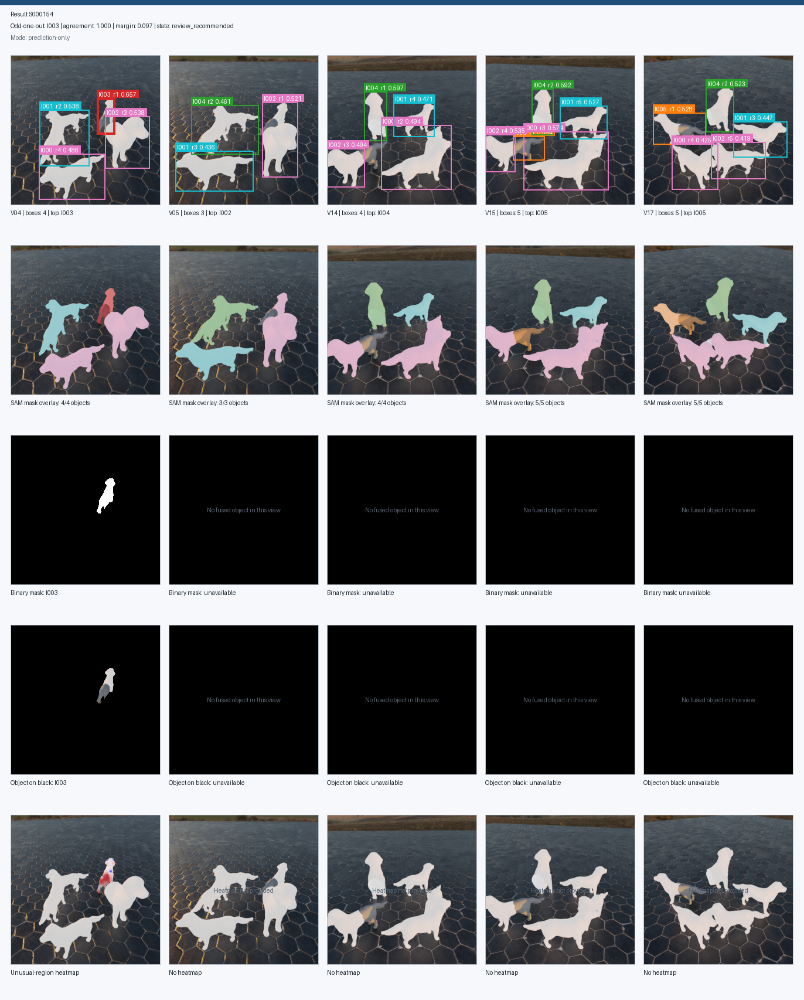

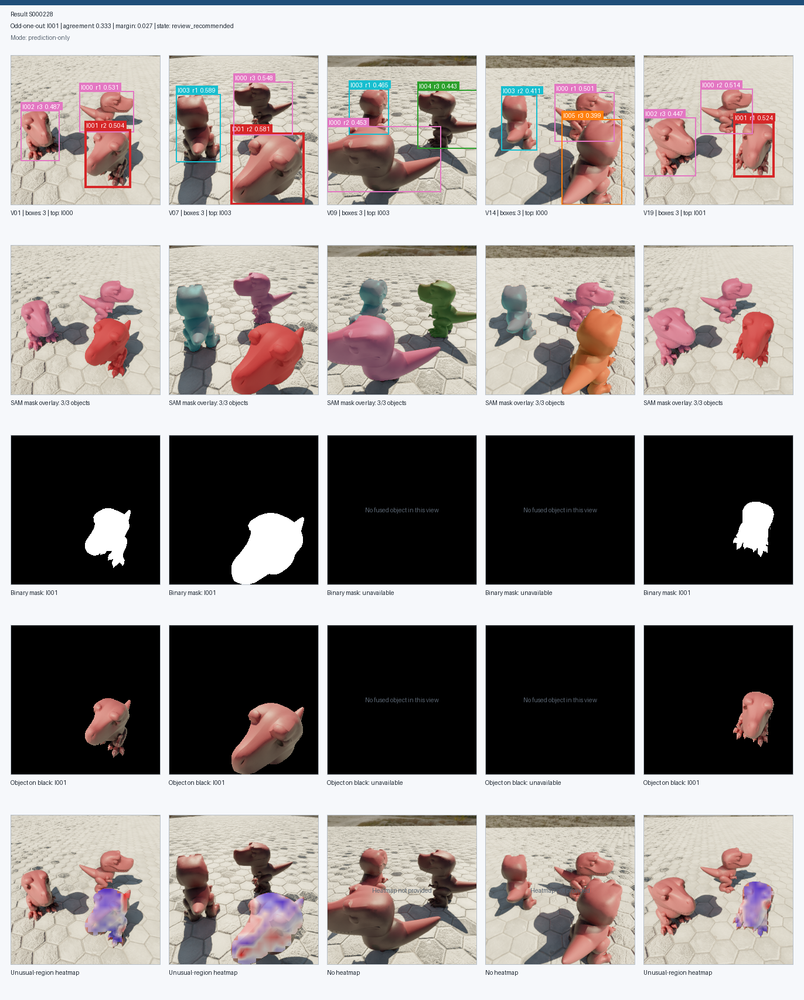

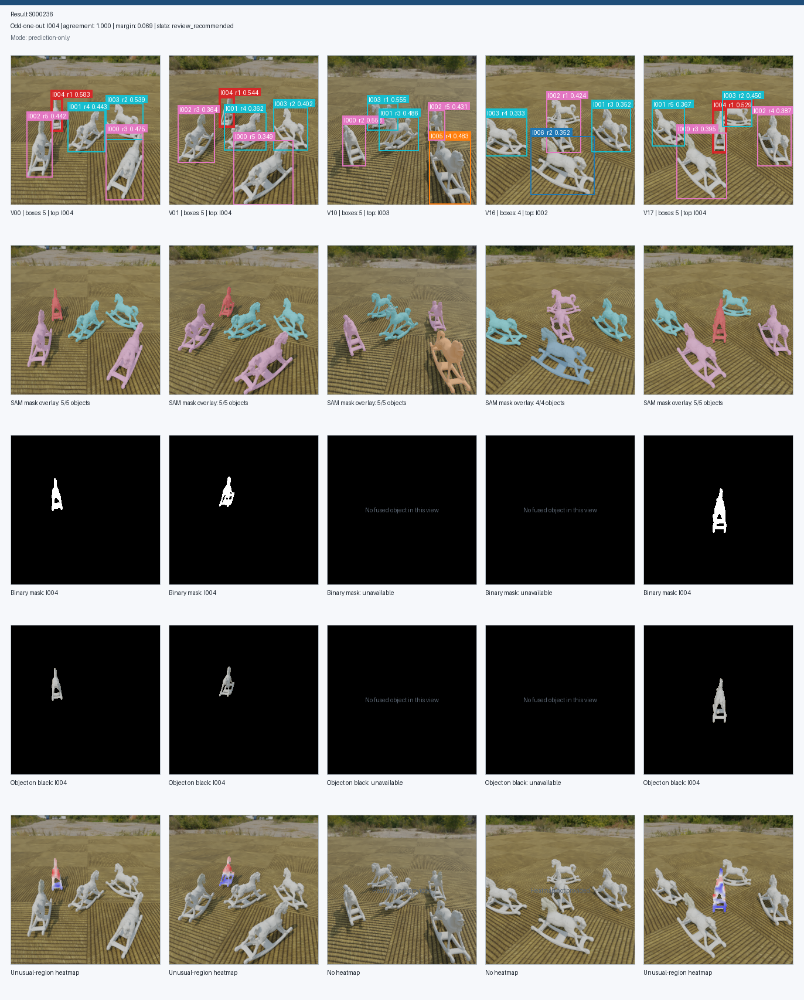

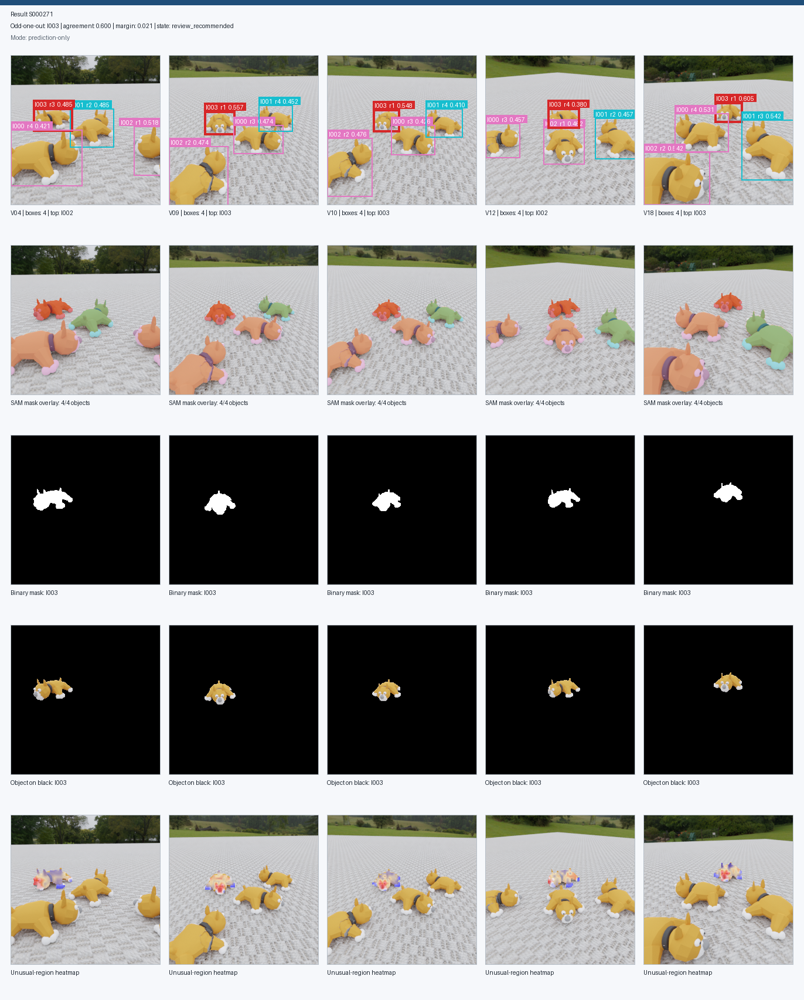

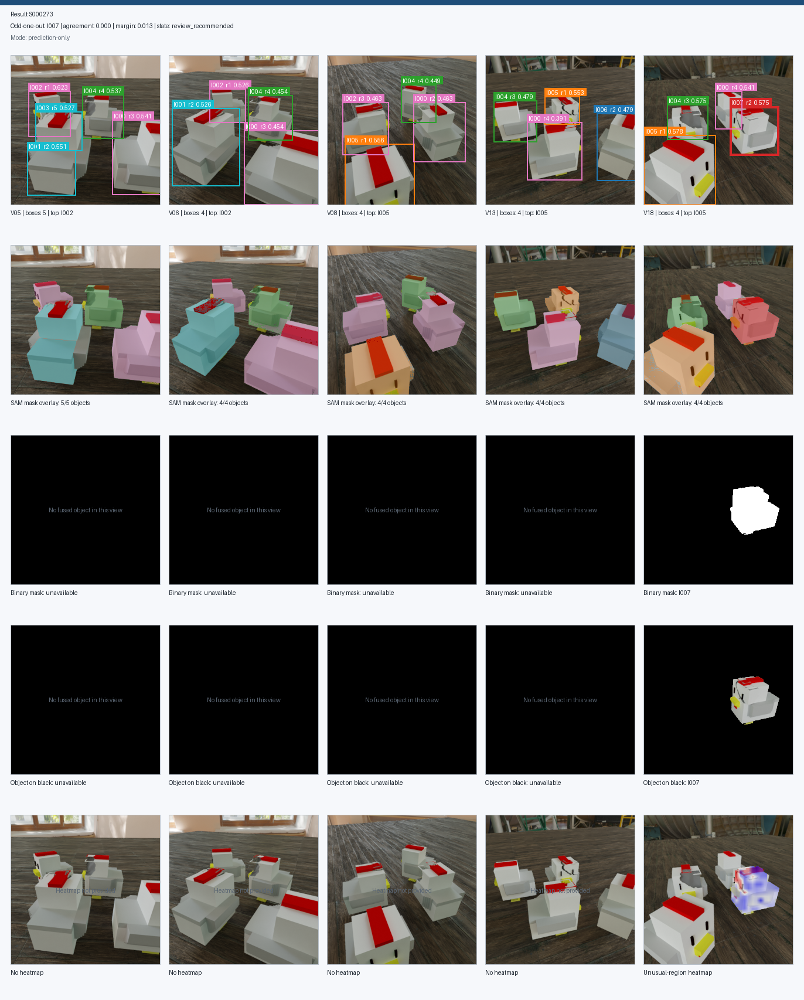

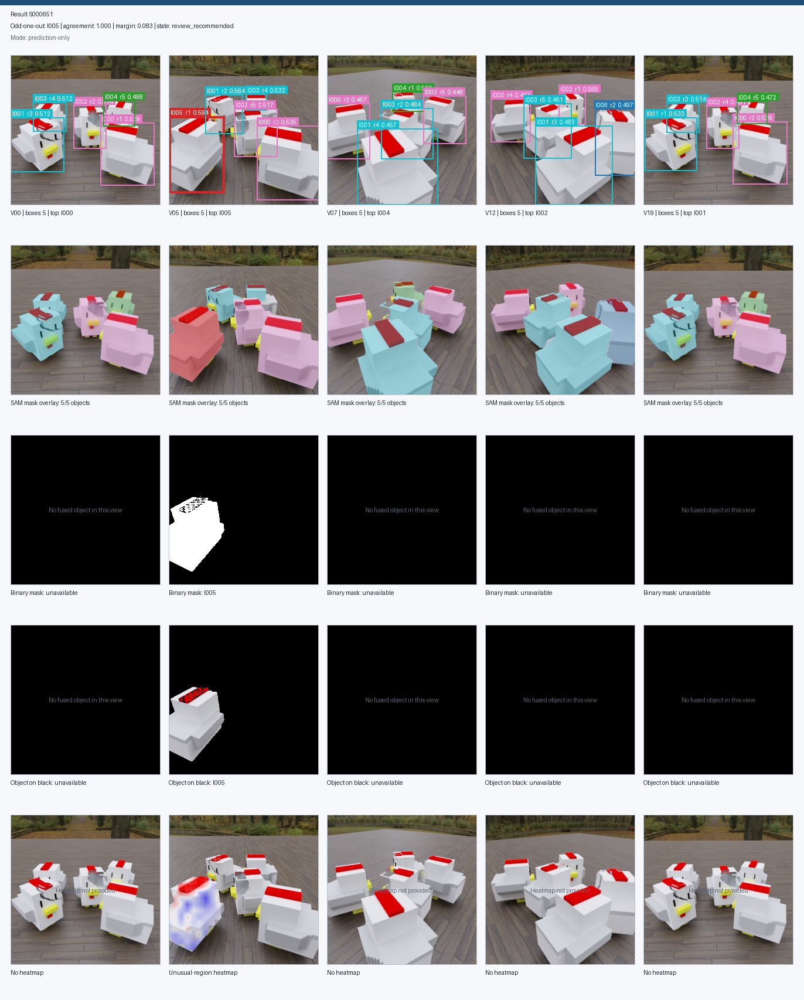

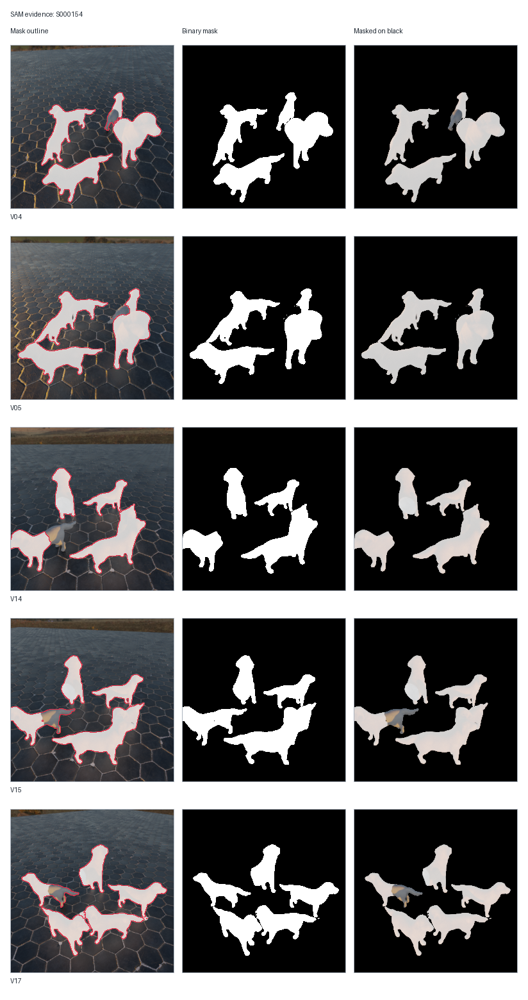

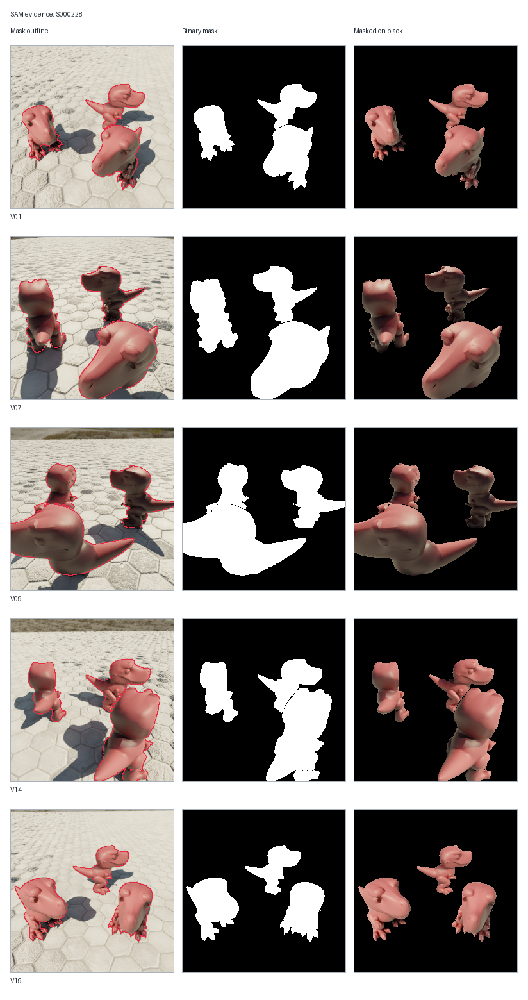

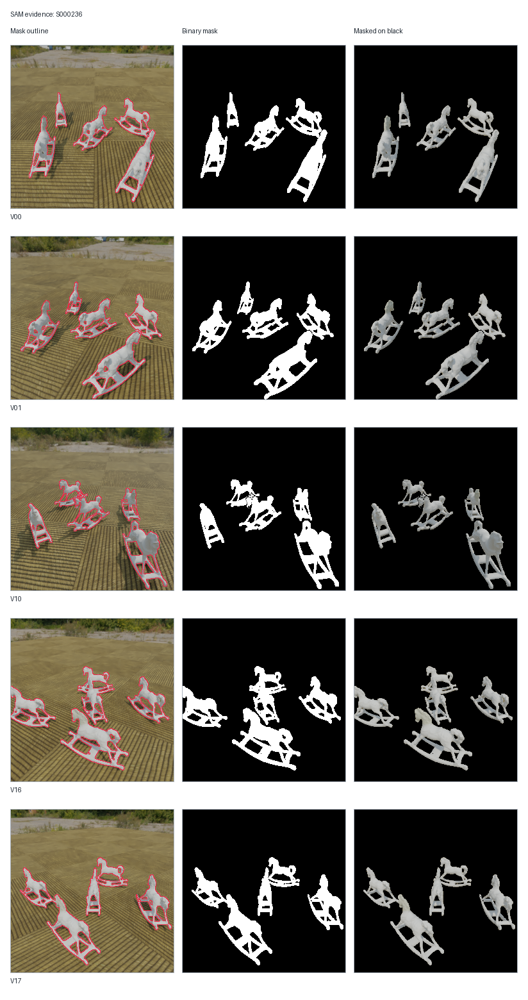

In [8]:
qualitative = pd.read_csv(OUTPUT_ROOT / "review-only" / "qualitative_manifest.csv")
display(qualitative[[
    "result_id", "fused_odd_one_out", "agreement", "margin", "review_state"
]])

for path in sorted((OUTPUT_ROOT / "review-only" / "figures" / "odd-one-out").glob("*-prediction.png"))[:6]:
    display(NotebookImage(filename=str(path)))
for path in sorted((OUTPUT_ROOT / "review-only" / "figures" / "odd-one-out").glob("*-sam-evidence.png"))[:3]:
    display(NotebookImage(filename=str(path)))

## Aggregate figures and saved evidence

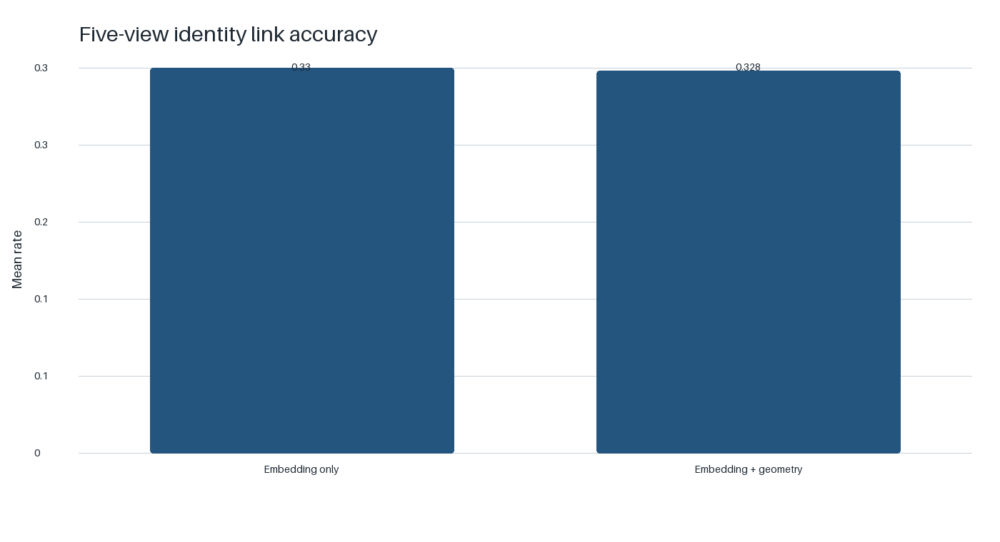

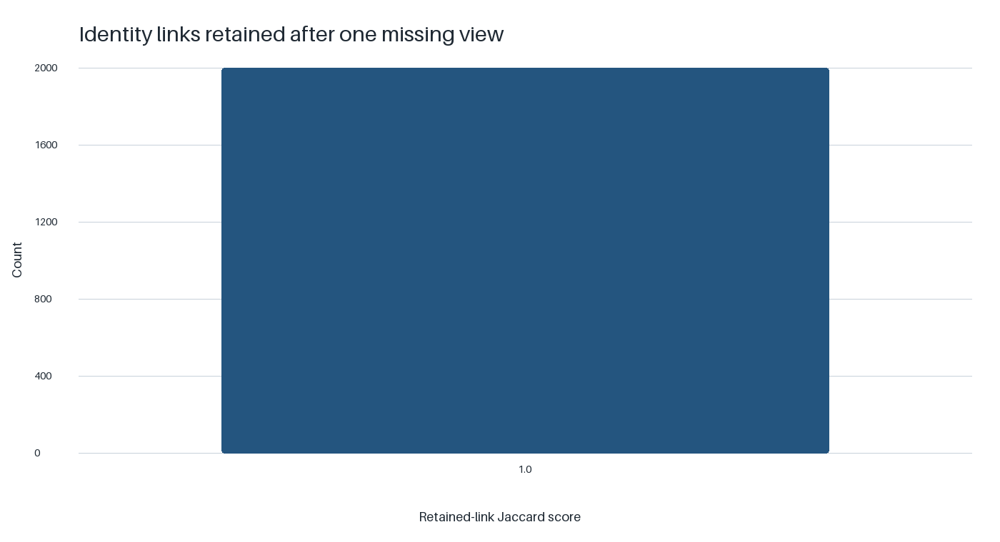

{'safe artifact count': 11,
 'safe artifact inventory SHA-256': 'fc4bea2884fbac1b9ca26b5a55a97ac86da60441ffc69e64f4d6b54167e70d79',
 'ClearML status': 'disabled',
 'ClearML task ID': None,
 'download root': '/kaggle/working/toysad8k_cross_view_identity_freeze',
 'minimal method resource': '/kaggle/working/toysad8k_cross_view_identity_freeze/publish/method-freeze'}

In [9]:
for name in (
    "five_view_identity_accuracy.png",
    "missing_view_link_stability.png",
):
    path = SAFE_ROOT / "figures" / name
    if path.is_file():
        display(NotebookImage(filename=str(path)))

artifact_manifest = json.loads(
    (SAFE_ROOT / "artifact_manifest.json").read_text(encoding="utf-8")
)
tracking_receipt = json.loads(
    (OUTPUT_ROOT / "tracking" / "clearml_receipt.json").read_text(encoding="utf-8")
)
display({
    "safe artifact count": artifact_manifest["artifact_count"],
    "safe artifact inventory SHA-256": artifact_manifest["artifact_inventory_sha256"],
    "ClearML status": tracking_receipt["status"],
    "ClearML task ID": tracking_receipt.get("task_id"),
    "download root": str(OUTPUT_ROOT),
    "minimal method resource": str(OUTPUT_ROOT / "publish" / "method-freeze"),
})

## Result boundary

Notebook 08F freezes the cross-view identity method and the versioned application result shape. It does not use calibration or internal-lock data to select the method. The next stage may run the frozen automatic pipeline on calibration RGB, lock those predictions, and only then use calibration labels to set the review policy. Internal-lock RGB and labels remain sealed until the final audit.

The published resource includes the exact base-model identity hash inherited from Notebook 08E. Every protected and official prediction notebook must rebuild that identity from its selected prompt and model configuration and reject the run before GPU inference if the identity differs.

Publish only `publish/method-freeze` as the private Kaggle dataset `vpi-toysad-development-method-freeze`. Later prediction-only notebooks must not mount the complete Notebook 08F output because it also contains development evaluator evidence.

The web application can be built after the automatic route, cross-view identity, odd-one-out fusion, and review policy have passed their declared integrity and evaluation checks. Human correction stays available as a separate review action and must never replace reporting of the automatic result.